# Equivariant Graph Neural Networks
## AI INFN Hackathon@Ferrara · 2 December 2026
**Alessandro Gabbana** ([alessandro.gabbana@unife.it](mailto:alessandro.gabbana@unife.it)) · **André Freitas** ([Andre.Freitas@roma2.infn.it](mailto:Andre.Freitas@roma2.infn.it))

In this notebook we will add incremental structure to a Graph Neural Network

We use a simple 2D particle system as a concrete testbed. Particles attract each
other via short-range spring-like forces within a cutoff radius. We will train
a message-passing GNN to predict the **per-particle acceleration** (force field)
from the current positions and velocities.

Then we will check three symmetries empirically:

1. **Permutation invariance** 
2. **Translation invariance** 
3. **Rotation equivariance** 


## 1. The Toy Problem

We simulate $N$ particles in a 2D box. Each particle $i$ has:

- position $\mathbf{x}_i \in \mathbb{R}^2$
- velocity $\mathbf{v}_i \in \mathbb{R}^2$
- acceleration $\mathbf{a}_i \in \mathbb{R}^2$

The acceleration is given by a sum of pairwise *spring-like* forces over all neighbours within a cutoff radius $r_c$:

$$
\mathbf{a}_i \;=\; \sum_{j \in \mathcal{N}(i)}
\; -k \,\bigl(\| \mathbf{x}_i - \mathbf{x}_j \| - r_0 \bigr)
\,\frac{\mathbf{x}_i - \mathbf{x}_j}{\| \mathbf{x}_i - \mathbf{x}_j \|}
$$

where $k$ is the spring constant and $r_0$ the rest length.

Time evolution is given by Euler integration with periodic boundary conditions.


In [1]:
import math
import torch
import matplotlib.pyplot as plt


def minimum_image(delta, box_size):
    """Map a displacement vector into the central image under periodic BC."""
    return (delta + box_size / 2) % box_size - box_size / 2


def compute_accelerations(pos, r_c, k, r_0, box_size):
    """
    Vectorised pairwise spring force with a cutoff radius.
    Returns the acceleration on each particle.
    """
    # all pairwise displacements with periodic wrap
    diff = pos.unsqueeze(0) - pos.unsqueeze(1)              # (N, N, 2)
    diff = minimum_image(diff, box_size)
    dist = diff.norm(dim=-1)                                # (N, N)

    # mask: neighbours within cutoff, exclude self
    mask = (dist < r_c) & (dist > 0)
    safe_dist = dist.clamp(min=1e-6)

    # spring force on i from j
    force_per_pair = -k * (safe_dist - r_0).unsqueeze(-1) * (diff / safe_dist.unsqueeze(-1))
    force_per_pair = force_per_pair * mask.unsqueeze(-1)

    return force_per_pair.sum(dim=1)


def simulate(num_particles=20, steps=250, dt=0.1, r_c=1.5, k=0.05, r_0=1.0, box_size=5.0):
    """Generate a trajectory of the particle system with periodic BC."""

    pos = torch.rand(num_particles, 2) * box_size
    vel = (torch.rand(num_particles, 2) - 0.5) * 0.5

    trajectory = []
    for _ in range(steps):
        acc = compute_accelerations(pos, r_c, k, r_0, box_size)
        trajectory.append({'pos': pos.clone(), 'vel': vel.clone(), 'acc': acc.clone()})
        vel = vel + dt * acc
        pos = (pos + dt * vel) % box_size                   # periodic BC

    return trajectory


Matplotlib is building the font cache; this may take a moment.


In [2]:
trajectory = simulate(num_particles=20, steps=250, box_size=5.0)
print(f"Generated {len(trajectory)} snapshots of {trajectory[0]['pos'].shape[0]} particles.")


Generated 250 snapshots of 20 particles.


A quick look at the initial configuration and the force field acting on it.


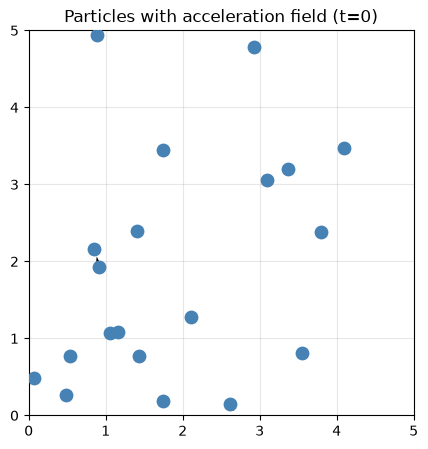

In [3]:
def plot_snapshot(state, box_size=5.0, title=""):
    pos, acc = state['pos'], state['acc']
    plt.figure(figsize=(5, 5))
    plt.scatter(pos[:, 0], pos[:, 1], s=80, c='steelblue', zorder=3)
    plt.quiver(pos[:, 0], pos[:, 1], acc[:, 0], acc[:, 1],
               angles='xy', scale_units='xy', scale=0.5,
               color='black', width=0.004)
    plt.xlim(0, box_size); plt.ylim(0, box_size)
    plt.gca().set_aspect('equal')
    plt.title(title); plt.grid(alpha=0.3)
    plt.show()


plot_snapshot(trajectory[0], title="Particles with acceleration field (t=0)")


## 2. The Interaction Graph

At each timestep we build a graph: each particle is a node, with an edge
between particles closer than $r_c$ (the same cutoff used by the physics).


In [4]:
from torch_cluster import radius_graph


# if torch_cluster gives problems, comment the import and use this code,
# not very efficient, but ok for small systems sizes we are playing with

# def radius_graph(pos, r, loop=False):
#     d = torch.cdist(pos, pos)
#     m = d < r
#     if not loop: m.fill_diagonal_(False)
#     return m.nonzero().t()  # [2, E]; O(N²), fine for these system sizes



def build_graph(pos, r_c=1.5):
    """
    Build an interaction graph from positions.
    Returns edge_index of shape (2, E) listing pairs (i, j) with d_ij < r_c.
    """
    return radius_graph(pos, r=r_c, loop=False)


edge_index = build_graph(trajectory[0]['pos'])
print(f"Built graph with {edge_index.shape[1]} edges on 20 nodes.")


Built graph with 100 edges on 20 nodes.


## 3. How We Will Test the Symmetries

The whole point of this notebook is to check empirically, after training each
model, whether the predicted force field respects the three symmetries we
care about. We package the three tests into one function we will reuse.

Each test takes the model, picks one snapshot, applies the symmetry
transformation to the input, and compares the transformed-input prediction
against the (appropriately-transformed) original prediction.

- **Permutation:** reorder particles -> predictions reorder identically.
- **Translation:** shift positions -> predictions unchanged.
- **Rotation:** rotate positions and velocities -> predictions rotate.


In [5]:
def rotate(vectors, angle):
    """Rotate 2D vectors by `angle` radians."""
    c, s = math.cos(angle), math.sin(angle)
    R = torch.tensor([[c, -s], [s, c]], dtype=vectors.dtype)
    return vectors @ R.T


def mse(a, b):
    return torch.nn.functional.mse_loss(a, b).item()


def test_all_symmetries(predict_fn, state, angle=math.pi / 4, offset=(1.0, -0.5)):
    """
    Run all three symmetry tests on a single snapshot.

    `predict_fn(pos, vel)` should return predicted accelerations for the
    given positions and velocities.
    """
    pos = state['pos']
    vel = state['vel']

    # ----- Permutation invariance -----
    perm = torch.randperm(pos.shape[0])
    a_orig = predict_fn(pos, vel)
    a_perm = predict_fn(pos[perm], vel[perm])
    a_perm_unperm = torch.zeros_like(a_perm)
    a_perm_unperm[perm] = a_perm
    err_perm = mse(a_orig, a_perm_unperm)

    # ----- Translation invariance -----
    offset_t = torch.tensor(offset)
    a_shifted = predict_fn(pos + offset_t, vel)
    err_trans = mse(a_orig, a_shifted)

    # ----- Rotation equivariance -----
    a_rot_input = predict_fn(rotate(pos, angle), rotate(vel, angle))
    a_orig_rotated = rotate(a_orig, angle)
    err_rot = mse(a_rot_input, a_orig_rotated)

    print(f"  Permutation invariance error (MSE): {err_perm:.3e}")
    print(f"  Translation invariance error (MSE): {err_trans:.3e}")
    print(f"  Rotation  equivariance  error (MSE): {err_rot:.3e}")

    return err_perm, err_trans, err_rot


## 4. A Generic Training Loop

We will train **four** different GNN architectures in this notebook. <br>
To focus on the *architecture* we factor the training loop into a single helper. <br>
Each model takes a `(pos, vel)` snapshot plus the edge index and returns predicted accelerations.


In [6]:
def make_samples(trajectory, r_c=1.5):
    """Pre-compute graph and inputs for every snapshot in the trajectory."""
    samples = []
    for state in trajectory:
        edge_index = build_graph(state['pos'], r_c)
        samples.append({
            'pos': state['pos'],
            'vel': state['vel'],
            'edge_index': edge_index,
            'y': state['acc'],
        })
    return samples


def train(model, samples, epochs=50, lr=1e-3, verbose=True):
    """Simple training loop. Model interface: forward(pos, vel, edge_index)."""
    optim = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        total = 0.0
        for s in samples:
            optim.zero_grad()
            pred = model(s['pos'], s['vel'], s['edge_index'])
            loss = loss_fn(pred, s['y'])
            loss.backward()
            optim.step()
            total += loss.item()
        if verbose and epoch % 10 == 0:
            print(f"  epoch {epoch:3d}  loss = {total / len(samples):.4f}")
    return model


def evaluate(model, state, r_c=1.5):
    """Wrap a trained model into a predict_fn for the symmetry tester."""
    def predict_fn(pos, vel):
        edge_index = build_graph(pos, r_c)
        with torch.no_grad():
            return model(pos, vel, edge_index)
    return test_all_symmetries(predict_fn, state)


samples = make_samples(trajectory)


## V1: Vanilla MP-GNN with Absolute Coordinates

We start with the most naive design: stack position and velocity as a 4-d node
feature, and feed pairs of these into a message MLP. The update concatenates
the aggregated message back with the absolute feature.

$$
\mathbf{m}_{ij} \;=\; \phi\bigl([\mathbf{h}_i, \mathbf{h}_j]\bigr),
\qquad
\mathbf{h}_i' \;=\; \gamma\bigl([\mathbf{h}_i,\; \textstyle\bigoplus_{j} \mathbf{m}_{ij}]\bigr)
$$

with $\mathbf{h}_i = (\mathbf{x}_i, \mathbf{v}_i)$.

The aggregator is a mean over neighbours, which gives us **permutation
invariance** for free. But the inputs to $\phi$ and $\gamma$ are absolute
coordinates, so we expect translation invariance and rotation equivariance
to fail.


In [7]:
import torch.nn as nn
from torch_geometric.nn import MessagePassing


class VanillaGNN(MessagePassing):
    """Naive MP-GNN: message MLP on concatenated absolute features."""

    def __init__(self, hidden=64):
        super().__init__(aggr='mean')
        self.phi = nn.Sequential(
            nn.Linear(8, hidden), nn.ReLU(), nn.Linear(hidden, hidden),
        )
        self.gamma = nn.Sequential(
            nn.Linear(4 + hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2),
        )

    def forward(self, pos, vel, edge_index):
        h = torch.cat([pos, vel], dim=1)             # (N, 4) — ABSOLUTE features
        return self.propagate(edge_index, h=h)

    def message(self, h_i, h_j):
        return self.phi(torch.cat([h_i, h_j], dim=1))

    def update(self, aggr_out, h):
        return self.gamma(torch.cat([h, aggr_out], dim=1))


/opt/miniconda3/envs/mzml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
print("Training vanilla GNN ...")
model_vanilla = train(VanillaGNN(), samples, epochs=50)

print("\nSymmetry test (Stage 1):")
evaluate(model_vanilla, trajectory[0]);


Training vanilla GNN ...


/opt/miniconda3/envs/mzml/lib/python3.12/site-packages/torch/cuda/__init__.py:422: UserWarning: Found GPU0 Quadro P520 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 11.0 which supports hardware CC >=11.0,<12.0
- 12.0 which supports hardware CC >=12.0,<13.0
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.13.0 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.13.0 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/opt/miniconda3/envs/mzml/lib/python3.12/site-packa

  epoch   0  loss = 0.0012
  epoch  10  loss = 0.0010
  epoch  20  loss = 0.0009
  epoch  30  loss = 0.0008
  epoch  40  loss = 0.0006

Symmetry test (Stage 1):
  Permutation invariance error (MSE): 1.819e-16
  Translation invariance error (MSE): 1.282e-03
  Rotation  equivariance  error (MSE): 3.158e-03


## V2: Relative Coordinates in the Message

Replace the absolute inputs to $\phi$ with quantities that are invariant
under translation: the relative position $\mathbf{r}_{ij} = \mathbf{x}_j -
\mathbf{x}_i$, the relative velocity $\mathbf{v}_{ij} = \mathbf{v}_j -
\mathbf{v}_i$, and the scalar distance $d_{ij} = \|\mathbf{r}_{ij}\|$.

$$
\mathbf{m}_{ij} \;=\; \phi\bigl([\mathbf{r}_{ij},\; \mathbf{v}_{ij},\; d_{ij}]\bigr)
$$



In [9]:
class RelativeMessageGNN(MessagePassing):
    """Message uses relative quantities; update still uses absolute features."""

    def __init__(self, hidden=64):
        super().__init__(aggr='mean')
        # message takes [rel_pos (2), rel_vel (2), dist (1)] = 5 dims
        self.phi = nn.Sequential(
            nn.Linear(5, hidden), nn.ReLU(), nn.Linear(hidden, hidden),
        )
        # update still concatenates absolute features (BAD)
        self.gamma = nn.Sequential(
            nn.Linear(4 + hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2),
        )

    def forward(self, pos, vel, edge_index):
        h = torch.cat([pos, vel], dim=1)
        return self.propagate(edge_index, h=h)

    def message(self, h_i, h_j):
        pos_i, vel_i = h_i[:, :2], h_i[:, 2:]
        pos_j, vel_j = h_j[:, :2], h_j[:, 2:]
        rel_pos = pos_j - pos_i
        rel_vel = vel_j - vel_i
        dist = rel_pos.norm(dim=1, keepdim=True)
        return self.phi(torch.cat([rel_pos, rel_vel, dist], dim=1))

    def update(self, aggr_out, h):
        return self.gamma(torch.cat([h, aggr_out], dim=1))


In [10]:
print("Training Stage-2 GNN (relative message, absolute update) ...")
model_s2 = train(RelativeMessageGNN(), samples, epochs=50)

print("\nSymmetry test (Stage 2):")
evaluate(model_s2, trajectory[0]);


Training Stage-2 GNN (relative message, absolute update) ...
  epoch   0  loss = 0.0010
  epoch  10  loss = 0.0003
  epoch  20  loss = 0.0002
  epoch  30  loss = 0.0002
  epoch  40  loss = 0.0002

Symmetry test (Stage 2):
  Permutation invariance error (MSE): 9.975e-18
  Translation invariance error (MSE): 2.001e-04
  Rotation  equivariance  error (MSE): 6.211e-03


## V3: Drop the Absolute Features Entirely

We modify the update so it only sees the aggregated message, never the raw absolute features.

$$
\mathbf{h}_i' \;=\; \gamma\bigl(\textstyle\bigoplus_{j} \mathbf{m}_{ij}\bigr)
$$


In [11]:
class FullyRelativeGNN(MessagePassing):
    """Update uses only the aggregated message — no absolute features anywhere."""

    def __init__(self, hidden=64):
        super().__init__(aggr='mean')
        self.phi = nn.Sequential(
            nn.Linear(5, hidden), nn.ReLU(), nn.Linear(hidden, hidden),
        )
        self.gamma = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2),
        )

    def forward(self, pos, vel, edge_index):
        h = torch.cat([pos, vel], dim=1)
        return self.propagate(edge_index, h=h)

    def message(self, h_i, h_j):
        pos_i, vel_i = h_i[:, :2], h_i[:, 2:]
        pos_j, vel_j = h_j[:, :2], h_j[:, 2:]
        rel_pos = pos_j - pos_i
        rel_vel = vel_j - vel_i
        dist = rel_pos.norm(dim=1, keepdim=True)
        return self.phi(torch.cat([rel_pos, rel_vel, dist], dim=1))

    def update(self, aggr_out, h):
        return self.gamma(aggr_out)


In [12]:
print("Training Stage-3 GNN (fully relative) ...")
model_s3 = train(FullyRelativeGNN(), samples, epochs=50)

print("\nSymmetry test (Stage 3):")
evaluate(model_s3, trajectory[0]);


Training Stage-3 GNN (fully relative) ...
  epoch   0  loss = 0.0010
  epoch  10  loss = 0.0003
  epoch  20  loss = 0.0003
  epoch  30  loss = 0.0002
  epoch  40  loss = 0.0002

Symmetry test (Stage 3):
  Permutation invariance error (MSE): 8.066e-18
  Translation invariance error (MSE): 6.824e-17
  Rotation  equivariance  error (MSE): 2.702e-04


## V4: Equivariant by Construction

The recipe:

1. From the equivariant vector inputs $\mathbf{r}_{ij}, \mathbf{v}_{ij}$, compute **only rotation-invariant scalars**:

$$
d_{ij}^2 = \|\mathbf{r}_{ij}\|^2, \quad
\langle \mathbf{r}_{ij}, \mathbf{v}_{ij} \rangle, \quad
\|\mathbf{v}_{ij}\|^2
$$

2. Pass these scalars through MLPs to obtain *scalar weights*, purely rotation-invariant quantities.

3. Build the equivariant message by multiplying scalar weights by the equivariant vectors:

$$
\mathbf{m}_{ij}
\;=\; \phi\bigl(d_{ij}^2,\; \langle \mathbf{r}_{ij}, \mathbf{v}_{ij}\rangle,\; \|\mathbf{v}_{ij}\|^2 \bigr)
\,\mathbf{r}_{ij}
\;+\; \psi\bigl(d_{ij}^2,\; \langle \mathbf{r}_{ij}, \mathbf{v}_{ij}\rangle,\; \|\mathbf{v}_{ij}\|^2 \bigr)
\,\mathbf{v}_{ij}
$$

The MLPs ($\phi$, $\psi$) act on rotation-invariant inputs and produce
rotation-invariant scalar outputs. The vectors $\mathbf{r}_{ij}$ and
$\mathbf{v}_{ij}$ rotate with the input. Their product (scalar x vector)
**rotates as a vector**: rotation equivariance is achieved by construction.

The aggregation (mean over neighbours) preserves equivariance because each
summand is already equivariant. The update is the identity.


In [13]:
class EquivariantGNN(MessagePassing):
    """
    Equivariant by construction.

    MLPs only ever see rotation-invariant scalars.
    Equivariant outputs are built as (scalar) x (equivariant vector).
    """

    def __init__(self, hidden=64):
        super().__init__(aggr='mean')
        # phi and psi: scalars -> scalar weights
        self.phi = nn.Sequential(
            nn.Linear(3, hidden), nn.ReLU(), nn.Linear(hidden, 1),
        )
        self.psi = nn.Sequential(
            nn.Linear(3, hidden), nn.ReLU(), nn.Linear(hidden, 1),
        )

    def forward(self, pos, vel, edge_index):
        # pass pos and vel separately so they are accessible in `message`
        return self.propagate(edge_index, pos=pos, vel=vel)

    def message(self, pos_i, pos_j, vel_i, vel_j):
        r_ij = pos_j - pos_i                                # vector
        v_ij = vel_j - vel_i                                # vector

        # Three rotation-invariant scalars per edge
        d2      = (r_ij * r_ij).sum(dim=1, keepdim=True)
        r_dot_v = (r_ij * v_ij).sum(dim=1, keepdim=True)
        v2      = (v_ij * v_ij).sum(dim=1, keepdim=True)
        scalars = torch.cat([d2, r_dot_v, v2], dim=1)        # (E, 3)

        # Scalar weights × equivariant vectors → equivariant message
        w_r = self.phi(scalars)                              # (E, 1)
        w_v = self.psi(scalars)                              # (E, 1)
        return w_r * r_ij + w_v * v_ij

    def update(self, aggr_out, pos, vel):
        return aggr_out                                      # identity update


In [14]:
print("Training Stage-4 (equivariant) GNN ...")
model_eq = train(EquivariantGNN(), samples, epochs=50)

print("\nSymmetry test (Stage 4):")
evaluate(model_eq, trajectory[0]);


Training Stage-4 (equivariant) GNN ...
  epoch   0  loss = 0.0011
  epoch  10  loss = 0.0005
  epoch  20  loss = 0.0004
  epoch  30  loss = 0.0004
  epoch  40  loss = 0.0004

Symmetry test (Stage 4):
  Permutation invariance error (MSE): 2.742e-19
  Translation invariance error (MSE): 7.325e-17
  Rotation  equivariance  error (MSE): 1.784e-16


## Summary

| Stage | Message input | Update input | Permutation | Translation | Rotation |
|-------|---------------|--------------|:-----------:|:-----------:|:--------:|
| 1     | absolute $(\mathbf{x}_i, \mathbf{v}_i)$ pairs       | absolute features | ✓ | ✗ | ✗ |
| 2     | relative $(\mathbf{r}_{ij}, \mathbf{v}_{ij}, d_{ij})$ | absolute features | ✓ | partly | ✗ |
| 3     | relative $(\mathbf{r}_{ij}, \mathbf{v}_{ij}, d_{ij})$ | aggregated only   | ✓ | ✓ | ✗ |
| 4     | invariant scalars only $\to$ scalars × equivariant vectors | identity | ✓ | ✓ | ✓ |



## More Fun: Rolling Out the Equivariant Model

Now that the model respects all three symmetries, we can use it as a learned
force field in an Euler integrator and roll out trajectories. 


Rolled out 50 steps with the equivariant GNN.


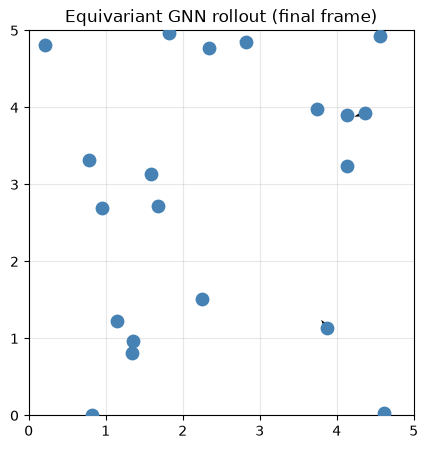

In [15]:
def rollout(model, init_state, steps=100, dt=0.1, r_c=1.5, box_size=5.0):
    pos = init_state['pos'].clone()
    vel = init_state['vel'].clone()
    traj = []
    model.eval()
    for _ in range(steps):
        edge_index = build_graph(pos, r_c)
        with torch.no_grad():
            acc = model(pos, vel, edge_index)
        traj.append({'pos': pos.clone(), 'vel': vel.clone(), 'acc': acc.clone()})
        vel = vel + dt * acc
        pos = (pos + dt * vel) % box_size
    return traj


traj_pred = rollout(model_eq, trajectory[0], steps=50)
print(f"Rolled out {len(traj_pred)} steps with the equivariant GNN.")
plot_snapshot(traj_pred[-1], title="Equivariant GNN rollout (final frame)")


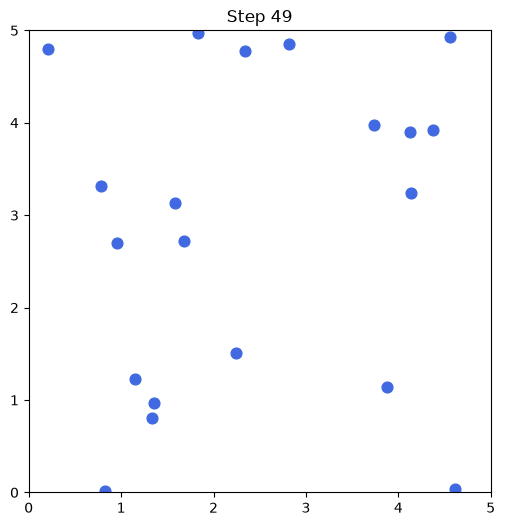

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

# Run rollout
# traj_pred = rollout(model_eq, trajectory[0], steps=50)

# --- Extract positions over time ---
positions = np.array([ step['pos'].cpu().numpy() for step in traj_pred])  # shape: (T, N, 2)

T, N, D = positions.shape

# --- Create animation ---
fig, ax = plt.subplots(figsize=(6, 6))

scat = ax.scatter([], [], s=60, c='royalblue')

ax.set_xlim(0, 5.0)
ax.set_ylim(0, 5.0)
ax.set_aspect('equal')

title = ax.set_title("Equivariant GNN Rollout")

def init():
    scat.set_offsets(np.empty((0, 2)))
    return scat,

def update(frame):
    pos = positions[frame]

    scat.set_offsets(pos)

    title.set_text(f"Step {frame}")

    return scat, title

anim = FuncAnimation(
    fig,
    update,
    frames=T,
    init_func=init,
    interval=100,
    blit=True
)

# Display in notebook
HTML(anim.to_jshtml())